# 01 EDA and balance check

**Stage 1.** Explore the data and check that treatment was randomized.

**Input:** 1M development sample

**Output:** EDA figures, balance table

**Steps**

- Distributions, summary stats, missing values and outliers.
- Conversion and visit rates by group.
- Randomization check: standardized feature differences, treated vs control.
- Average effect with a confidence interval, for visits and conversion.

Sample shape: (1000000, 16) | Treated share: 0.8503
Missing values: {'f0': 0, 'f1': 0, 'f2': 0, 'f3': 0, 'f4': 0, 'f5': 0, 'f6': 0, 'f7': 0, 'f8': 0, 'f9': 0, 'treatment': 0, 'visit': 0, 'conversion': 0}


,mean,std,min,50%,max
f0,19.627356,5.378435,12.616364,21.929188,26.745253
f1,10.069906,0.104665,10.059654,10.059654,15.069616
f2,8.446546,0.299340,8.214383,8.214383,9.051962
f3,4.180877,1.332388,-6.864334,4.679882,4.679882
f4,10.339132,0.342750,10.280525,10.280525,20.257305
f5,4.028174,0.431724,-6.828777,4.115453,4.115453
f6,-4.155865,4.575219,-27.900204,-2.411115,0.294443
f7,5.102936,1.208077,4.833815,4.833815,11.998078
f8,3.933585,0.056647,3.640858,3.971858,3.971858
f9,16.022446,7.012011,13.190056,13.190056,72.657166


visit           conversion           exposure          
            count      mean      count      mean    count      mean
treatment                                                          
0          149735  0.038221     149735  0.001910   149735  0.000000
1          850265  0.048862     850265  0.003192   850265  0.035963

VISIT ATE: 0.010642 (95% CI: [0.009568, 0.011715]), p=5.737e-84
CONVERSION ATE: 0.001282 (95% CI: [0.001030, 0.001533]), p=1.747e-23


,feature,mean_treated,mean_control,SMD,abs_SMD
3,f3,4.171030,4.236794,-0.050904,0.050904
6,f6,-4.184957,-3.990670,-0.043000,0.043000
5,f5,4.026200,4.039388,-0.031757,0.031757
1,f1,10.070313,10.067584,0.027556,0.027556
9,f9,16.046614,15.885207,0.023294,0.023294
8,f8,3.933405,3.934604,-0.021345,0.021345
7,f7,5.106522,5.082574,0.020092,0.020092
2,f2,8.446041,8.449415,-0.011241,0.011241
4,f4,10.339516,10.336957,0.007540,0.007540
0,f0,19.623941,19.646744,-0.004237,0.004237


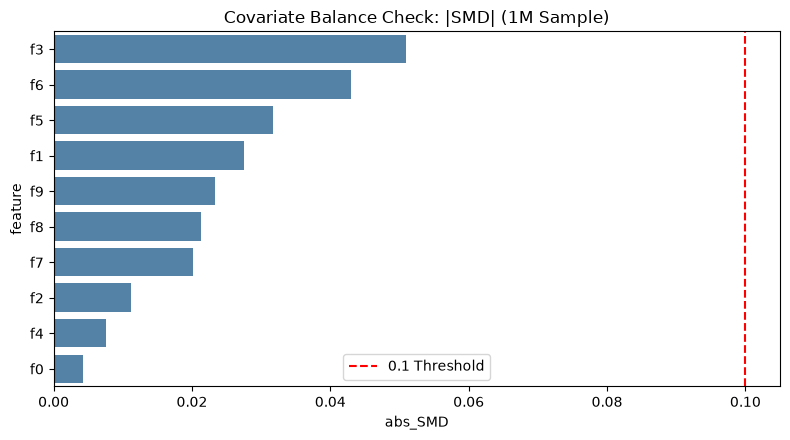

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

ROOT = Path.cwd().parent
sys.path.append(str(ROOT / "src"))
from uplift.data import FEATURES, TREATMENT, OUTCOMES, verify_checksum, to_parquet, draw_sample

# 1. Verify dataset & convert to fast parquet format
csv_gz = ROOT / "data" / "criteo-research-uplift-v2.1.csv.gz"
parquet_path = ROOT / "data" / "criteo.parquet"

assert verify_checksum(csv_gz), "SHA256 mismatch!"
to_parquet(csv_gz, parquet_path)

# 2. Load 1M sample & check missing values / summary stats
full_df = pd.read_parquet(parquet_path)
df = draw_sample(full_df, n=1_000_000)
del full_df

KEEP_FEATURES = FEATURES[:10]
print(f"Sample shape: {df.shape} | Treated share: {df[TREATMENT].mean():.4f}")
print("Missing values:", df[KEEP_FEATURES + [TREATMENT] + OUTCOMES].isna().sum().to_dict())
display(df[KEEP_FEATURES].describe().T[["mean", "std", "min", "50%", "max"]])

# 3. Visit & conversion rates + ATE with 95% CI
display(df.groupby(TREATMENT)[OUTCOMES + ["exposure"]].agg(["count", "mean"]))
for outcome in OUTCOMES:
    t = df.loc[df[TREATMENT] == 1, outcome]
    c = df.loc[df[TREATMENT] == 0, outcome]
    ate = t.mean() - c.mean()
    se = np.sqrt(t.var(ddof=1) / len(t) + c.var(ddof=1) / len(c))
    _, p_val = stats.ttest_ind(t, c, equal_var=False)
    print(f"{outcome.upper()} ATE: {ate:.6f} (95% CI: [{ate - 1.96*se:.6f}, {ate + 1.96*se:.6f}]), p={p_val:.3e}")

# 4. Randomization balance check (Standardized Mean Difference)
t_df, c_df = df[df[TREATMENT] == 1], df[df[TREATMENT] == 0]
rows = []
for col in KEEP_FEATURES:
    mt, mc = t_df[col].mean(), c_df[col].mean()
    vt, vc = t_df[col].var(ddof=1), c_df[col].var(ddof=1)
    smd = (mt - mc) / np.sqrt((vt + vc) / 2)
    rows.append({"feature": col, "mean_treated": mt, "mean_control": mc, "SMD": smd, "abs_SMD": abs(smd)})

balance_df = pd.DataFrame(rows).sort_values("abs_SMD", ascending=False)
display(balance_df)

results_dir = ROOT / "results"
results_dir.mkdir(exist_ok=True)
balance_df.to_csv(results_dir / "balance_table_1m.csv", index=False)

plt.figure(figsize=(8, 4.5))
sns.barplot(data=balance_df, x="abs_SMD", y="feature", color="steelblue")
plt.axvline(0.1, color="red", linestyle="--", label="0.1 Threshold")
plt.title("Covariate Balance Check: |SMD| (1M Sample)")
plt.legend()
plt.tight_layout()
plt.savefig(results_dir / "balance_smd_1m.png", dpi=150)
plt.show()